In [28]:

# Import libraries
import pandas as pd

# Load the Kaggle dataset
df = pd.read_csv("/content/spam.csv", encoding="latin-1")

# Select and rename useful columns
df = df[["v1", "v2"]]
df.columns = ["label", "message"]

# Remove duplicate and empty messages
df = df.drop_duplicates()
df = df.dropna(subset=["label", "message"])

# Show dataset information
print("Dataset loaded successfully!")
print("Total messages:", len(df))
print(df.head())


Dataset loaded successfully!
Total messages: 5169
  label                                            message
0   ham  Go until jurong point, crazy.. Available only ...
1   ham                      Ok lar... Joking wif u oni...
2  spam  Free entry in 2 a wkly comp to win FA Cup fina...
3   ham  U dun say so early hor... U c already then say...
4   ham  Nah I don't think he goes to usf, he lives aro...


Model Accuracy: 96.81%

Classification Report:
              precision    recall  f1-score   support

         ham       0.96      1.00      0.98       903
        spam       1.00      0.75      0.86       131

    accuracy                           0.97      1034
   macro avg       0.98      0.87      0.92      1034
weighted avg       0.97      0.97      0.97      1034



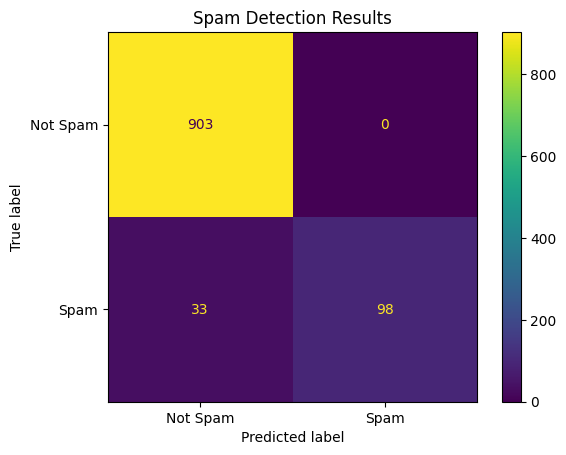

In [29]:

# Import ML tools
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, classification_report,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Separate messages and their labels
X = df["message"]
y = df["label"]

# Split data: 80% training, 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Create a pipeline to convert text and train the model
model = Pipeline([
    ("tfidf", TfidfVectorizer()),
    ("classifier", RandomForestClassifier(
        random_state=42, class_weight="balanced"
    ))
])

# Train the model
model.fit(X_train, y_train)

# Test the model
predictions = model.predict(X_test)

# Display results
accuracy = accuracy_score(y_test, predictions)
print(f"Model Accuracy: {accuracy * 100:.2f}%")

print("\nClassification Report:")
print(classification_report(y_test, predictions))

# Display confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test, predictions, labels=["ham", "spam"],
    display_labels=["Not Spam", "Spam"]
)
plt.title("Spam Detection Results")
plt.show()


In [34]:
# Function to check a message
def check_message(message):
    prediction = model.predict([message])[0]

    print("Message:", message)

    if prediction == "spam":
        print("Result: SPAM")
    else:
        print("Result: NORMAL")


# Test sample messages
check_message("URGENT! You have won a FREE prize. Call now to claim!")
check_message("Hello, how are you? See you tomorrow.")

Message: URGENT! You have won a FREE prize. Call now to claim!
Result: SPAM
Message: Hello, how are you? See you tomorrow.
Result: NORMAL
